In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [16]:
n = 100
k = 10**4

x = np.linspace(-(1/2), 1/2, n)
a = x[1]-x[0]

d2 = (np.eye(n, n,-1) + np.eye(n, n,1) -2*np.eye(n, n))/a**2


h = -0.5*d2 + np.diag(0.5*k*x**2)

eigenvalues , eigenvectors = np.linalg.eigh(h)


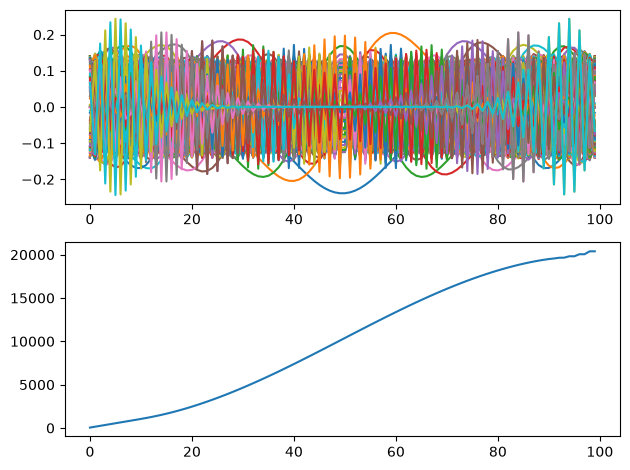

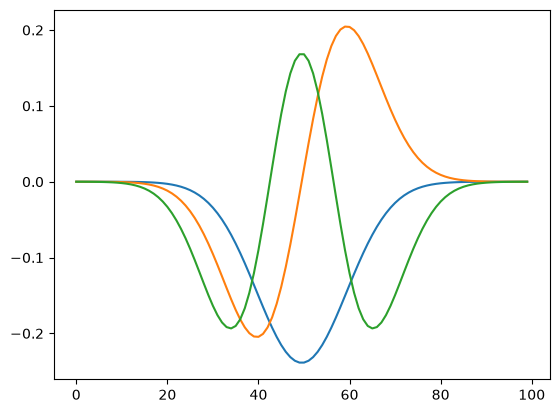

In [28]:
plt.subplot(2,1,1)
plt.plot(eigenvectors)
plt.subplot(2,1,2)
plt.plot(eigenvalues)
plt.tight_layout()
plt.show()

plt.plot(eigenvectors[:,0])
plt.plot(eigenvectors[:,1])
plt.plot(eigenvectors[:,2])
plt.show()


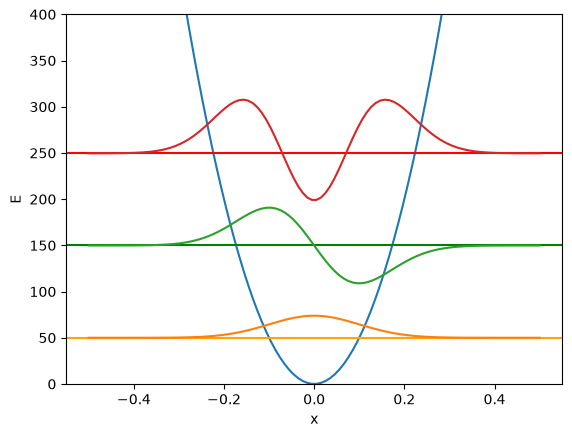

In [64]:
plt.plot(x,0.5*k*x**2)
plt.ylabel("E")
plt.xlabel("x")
plt.axhline(eigenvalues[0] , c = 'orange')
plt.axhline(eigenvalues[1] , c = 'green')
plt.axhline(eigenvalues[2] , c = 'red')
plt.ylim(0,400)
plt.plot(x, -eigenvectors[:,0] * 100 + eigenvalues[0])
plt.plot(x, -eigenvectors[:,1] * 200 + eigenvalues[1])
plt.plot(x, -eigenvectors[:,2] * 300 + eigenvalues[2])
plt.show()

In [65]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Pacote gaussiano inicial, deslocado do centro do potencial
hbar = 1.0
omega = np.sqrt(k)
sigma = 1 / np.sqrt(2 * omega)
x0 = -0.2
p0 = 0.0

psi0 = np.exp(-((x - x0) ** 2) / (4 * sigma**2) + 1j * p0 * x)
psi0 /= np.sqrt(a * np.sum(np.abs(psi0) ** 2))

# Projeta o pacote nos autoestados e aplica a fase temporal de cada energia
coeficientes = np.sqrt(a) * (eigenvectors.conj().T @ psi0)
periodo = 2 * np.pi / omega
tempos = np.linspace(0, 2 * periodo, 61)
funcoes_onda = np.array([
    (eigenvectors @ (coeficientes * np.exp(-1j * eigenvalues * t / hbar))) / np.sqrt(a)
    for t in tempos
])
densidades = np.abs(funcoes_onda) ** 2

fig, ax = plt.subplots(figsize=(8, 4))
linha, = ax.plot(x, densidades[0], color="royalblue", label=r"$|\psi(x,t)|^2$")
ax.plot(x, densidades[0], "--", color="gray", alpha=0.6, label="Distribuição inicial")
ax.set_xlim(x[0], x[-1])
ax.set_ylim(0, 1.1 * densidades.max())
ax.set_xlabel("x")
ax.set_ylabel(r"$|\psi(x,t)|^2$")
ax.legend()

def atualizar(frame):
    linha.set_ydata(densidades[frame])
    posicao_media = a * np.sum(x * densidades[frame])
    ax.set_title(f"Evolução temporal: t = {tempos[frame]:.4f}; ⟨x⟩ = {posicao_media:.3f}")
    return linha,

animacao = FuncAnimation(fig, atualizar, frames=len(tempos), interval=40, blit=False)
plt.close(fig)
display(HTML(animacao.to_jshtml()))